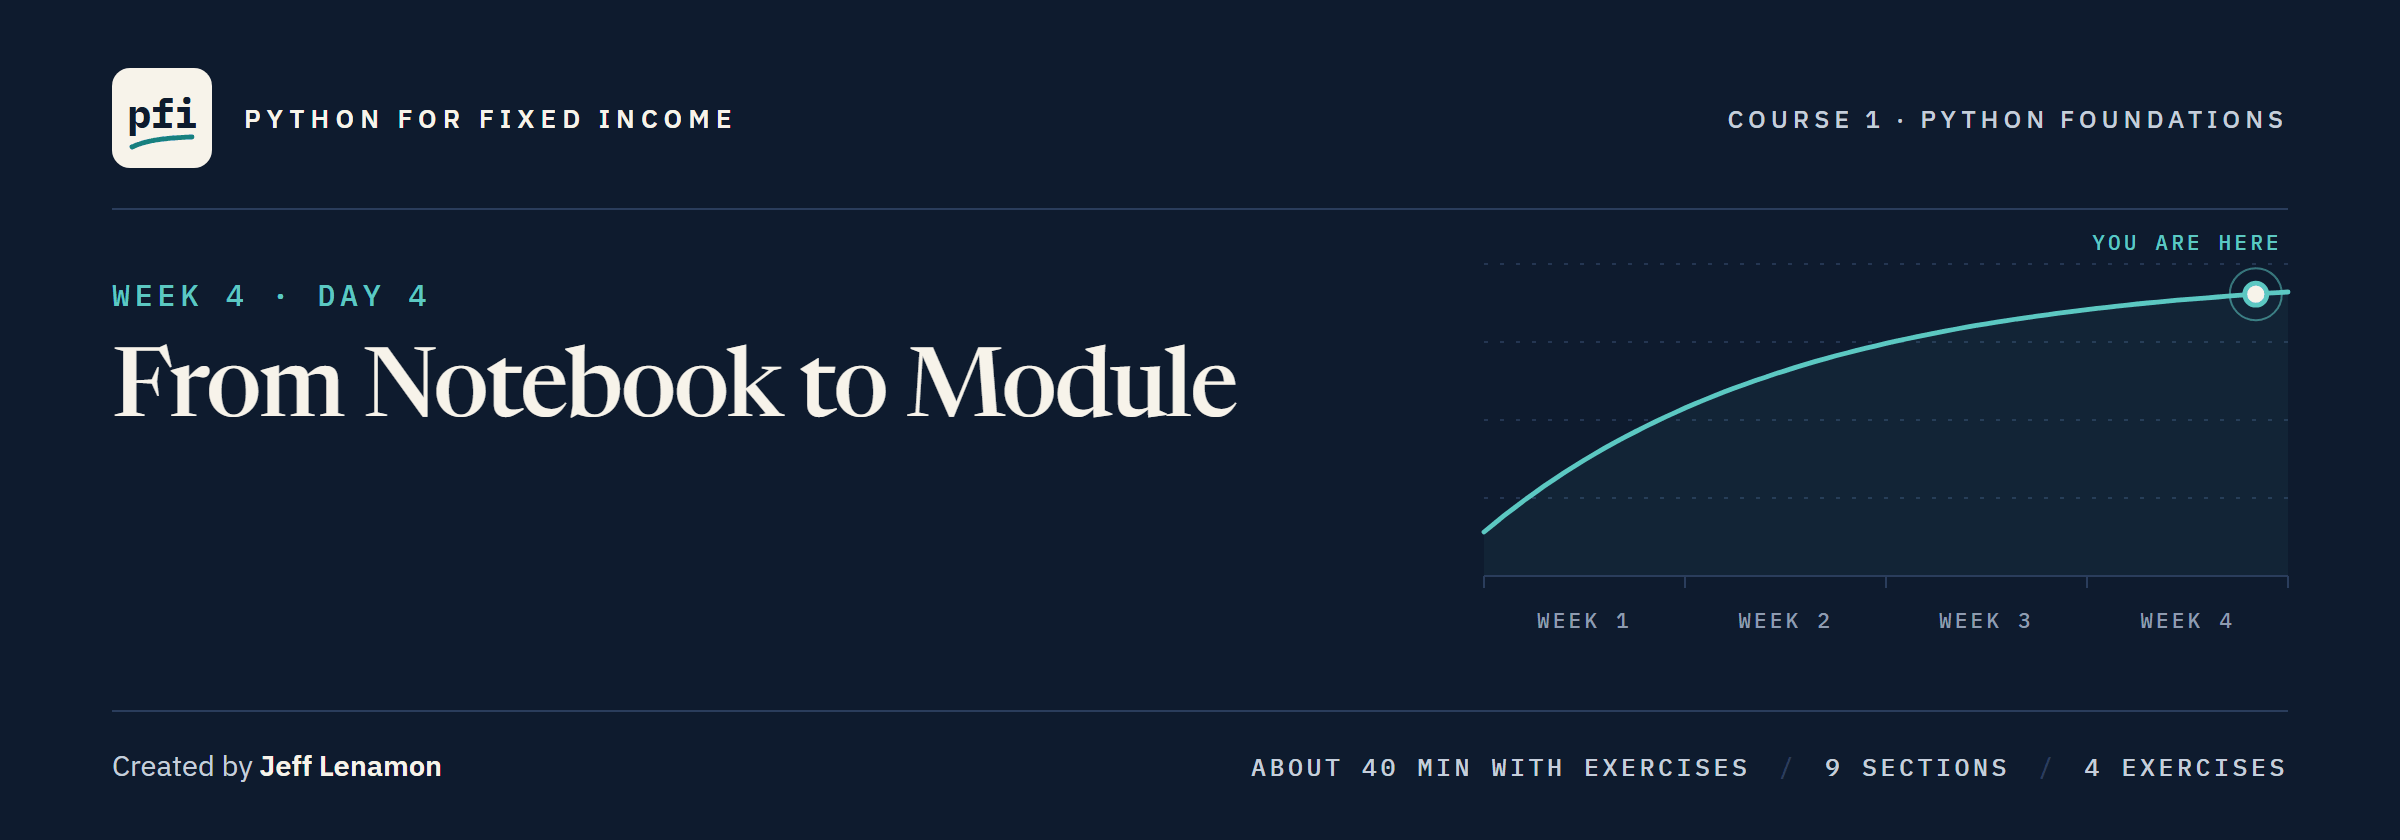

# From Notebook to Module

Week 4, Day 4. The EDA notebook's cleaning routine moves into a file of functions that any notebook can import.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week4/day4/19_from_notebook_to_module.ipynb)

## The Desk Lead's Note

> The EDA notebook's cleaning routine lives in one notebook, and October's extract arrives next month. Put it and its checks in one file anyone on the desk can import. Run it on September and tie the cover note. Count what it changes, and prove it leaves a file with no problems alone. Write me the workbook. Test the function itself, so an edit next year cannot break it quietly. And tell me which of our other spreadsheet jobs deserve the same.

A **module** is a plain text file ending in `.py` that holds functions; a notebook imports it and calls them.

<table align="left">
<tr><th align="left">September file</th><th align="left">What it is</th></tr>
<tr><td align="left"><code>holdings_messy.csv</code></td><td align="left">the extract as operations sent it, the EDA notebook's file</td></tr>
<tr><td align="left"><code>holdings.csv</code></td><td align="left">the same book, sent with no problems</td></tr>
</table>
<br clear="left">

The issuers are invented; every statement describes the data.

**One file holds the routine; the notebook only calls it.**

## Your Route Through Day 4

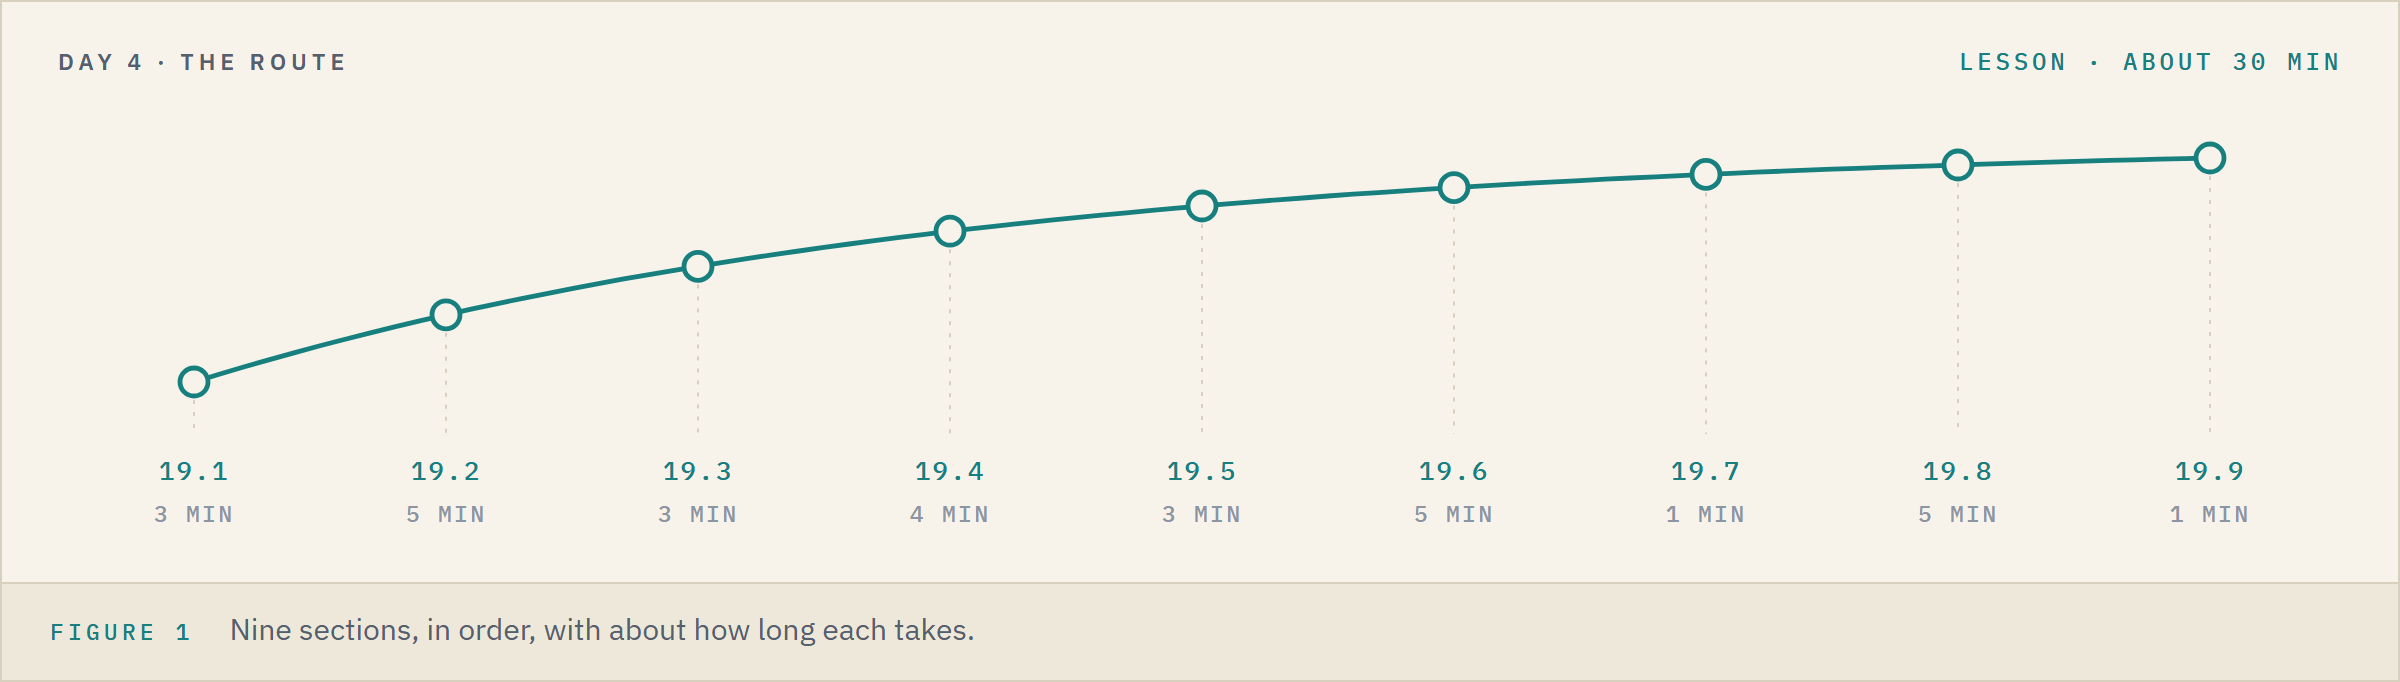

<table align="left">
<tr><th align="left"></th><th align="left">Section</th><th align="left">About</th></tr>
<tr><td align="left">19.1</td><td align="left">The Routine in a File</td><td align="left">3 min</td></tr>
<tr><td align="left">19.2</td><td align="left">What a Module Is</td><td align="left">5 min</td></tr>
<tr><td align="left">19.3</td><td align="left">Checks That Stop</td><td align="left">3 min</td></tr>
<tr><td align="left">19.4</td><td align="left">Edit the Module, Then Reload</td><td align="left">4 min</td></tr>
<tr><td align="left">19.5</td><td align="left">A Module That Is Also a Program</td><td align="left">3 min</td></tr>
<tr><td align="left">19.6</td><td align="left">The Same Lines on a Second File</td><td align="left">5 min</td></tr>
<tr><td align="left">19.7</td><td align="left">The Report Workbook</td><td align="left">1 min</td></tr>
<tr><td align="left">19.8</td><td align="left">Testing a Function</td><td align="left">5 min</td></tr>
<tr><td align="left">19.9</td><td align="left">Which Jobs to Move</td><td align="left">1 min</td></tr>
</table>
<br clear="left">

**Time.** About 30 minutes for the lesson, then about 12 for the four exercises.

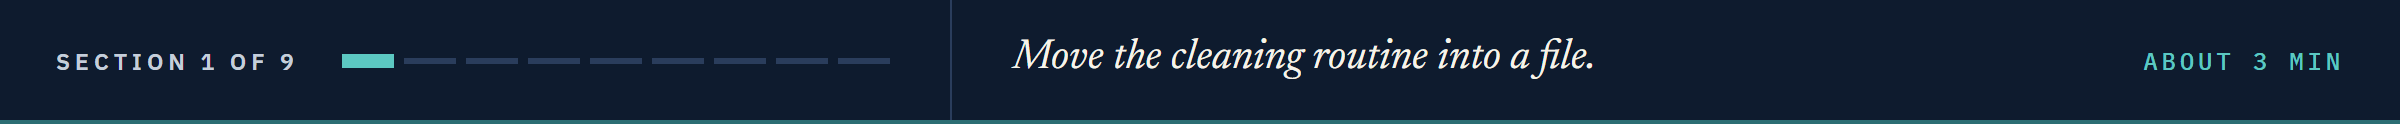

## 19.1 The Routine in a File

### Set Up, and No File Yet

Q. Set up, then look for `desk_tools.py` in this folder.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# the house greens and greys, as in the Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])
# sys holds Python's own settings. This one stops Python saving a compiled copy of a module
# in a __pycache__ folder, so the folder ends the day with only the files it started with.
sys.dont_write_bytecode = True
# the repo's data folder on your machine; in Colab, GitHub, as in pandas Part 1
if os.path.exists('../../../data/holdings_messy.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
# the cover note's three control totals
expected_bonds = 200
expected_face = 489_000_000
expected_value = 490_819_215
print(os.path.exists('desk_tools.py'))

False


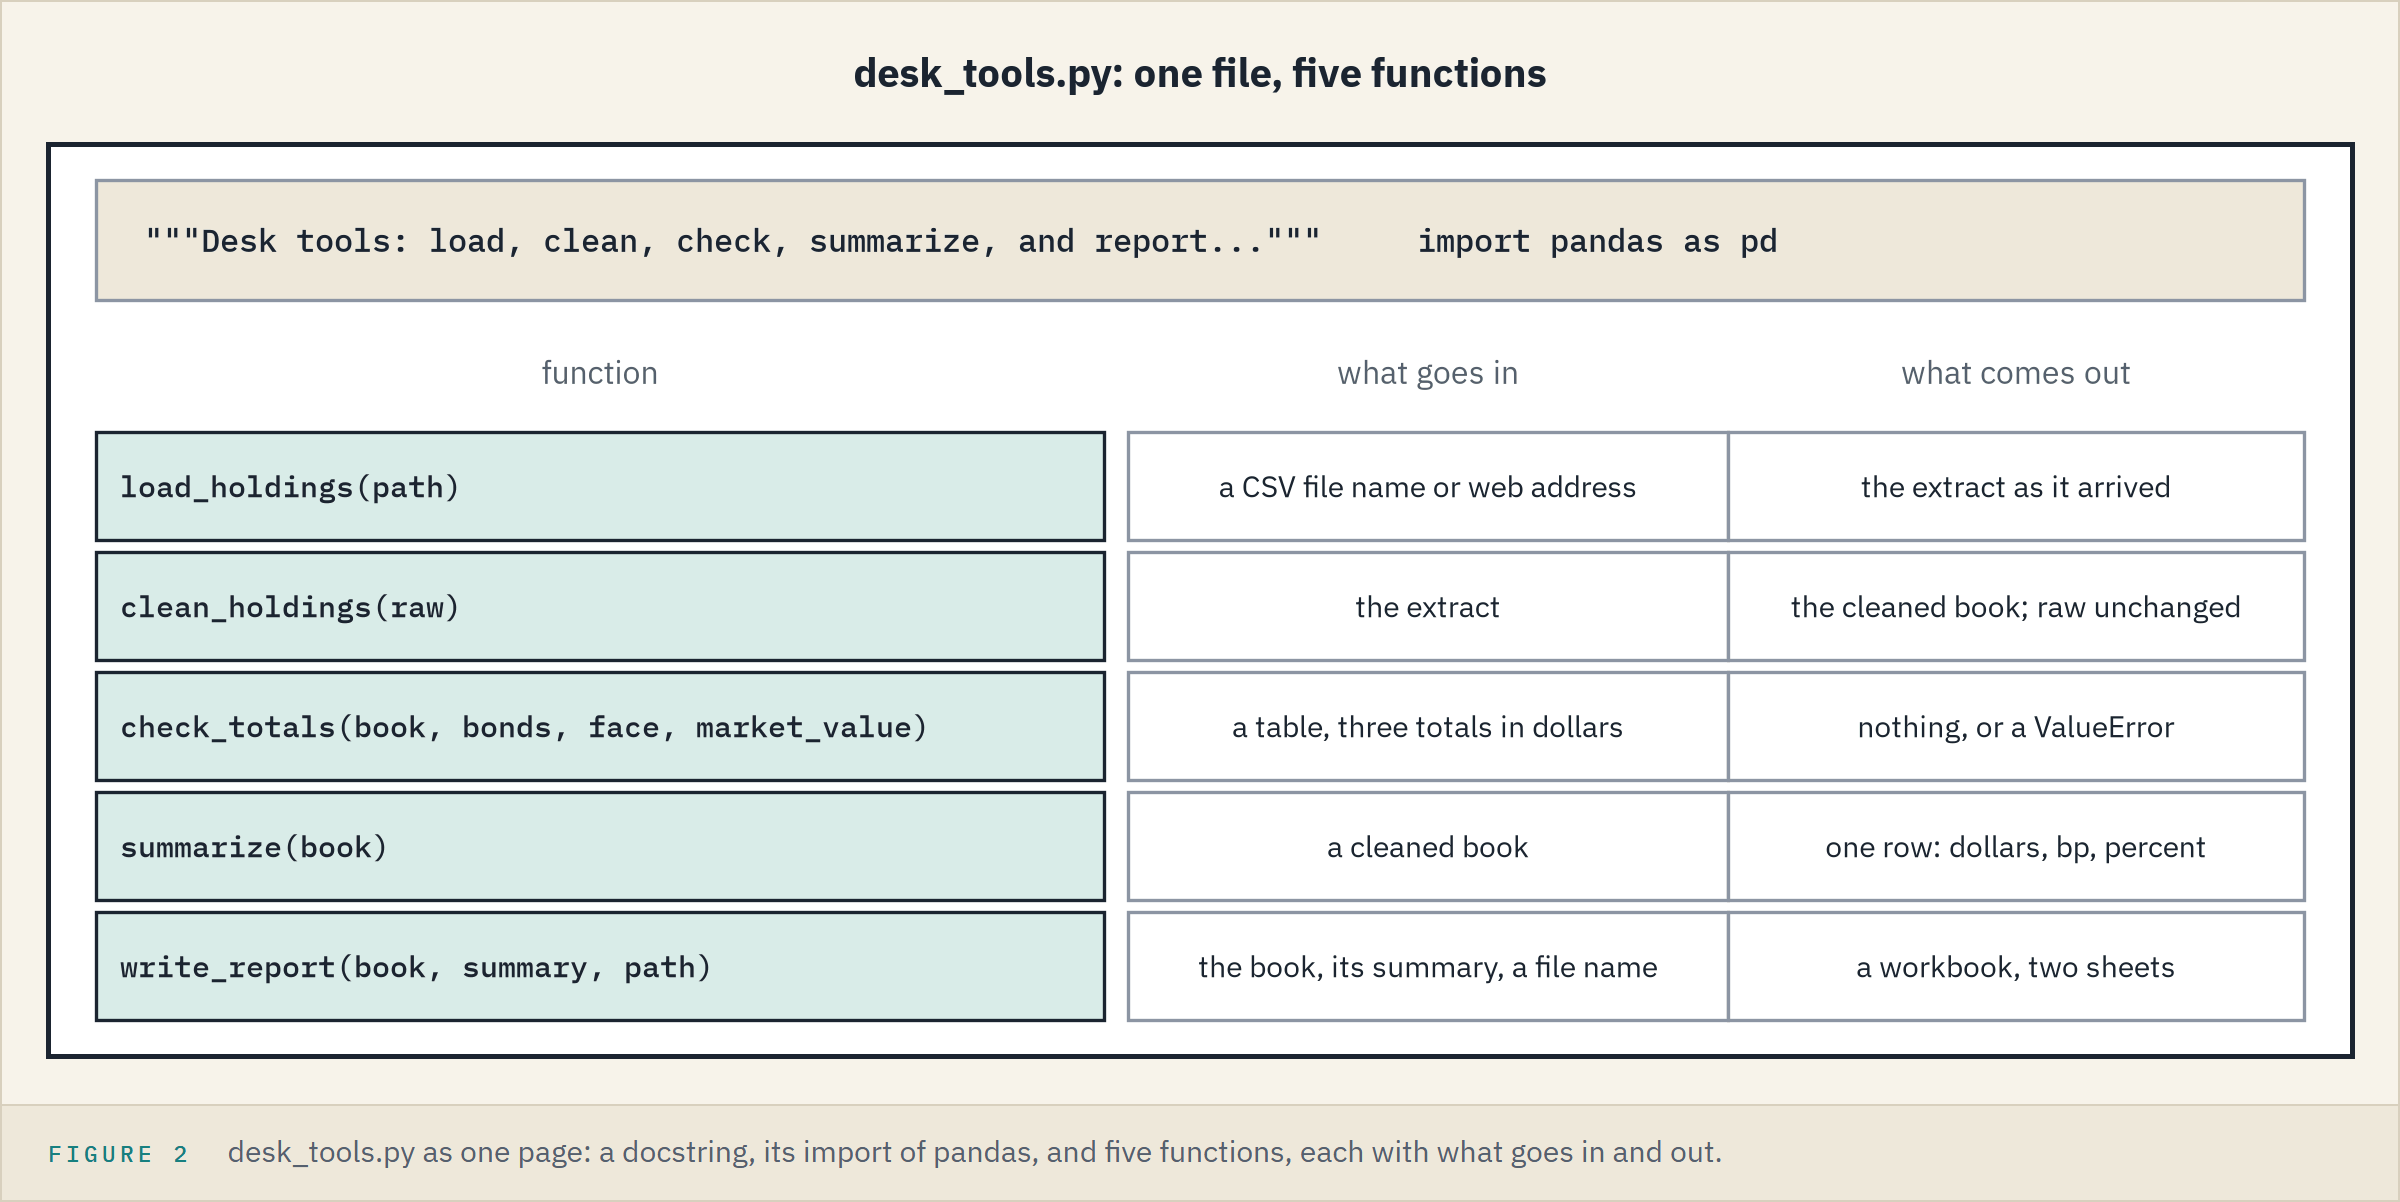

### Write `desk_tools.py`

As in Day 0, a cell that starts `%%writefile desk_tools.py` runs nothing: Jupyter saves the rest of the cell as that file.
One line, `load_holdings`'s first, carries notes on the types going in and out; 19.2 reads them.

Q. Write the module.

In [2]:
%%writefile desk_tools.py
"""Desk tools: load, clean, check, summarize, and report a month-end holdings extract.

From Python for Fixed Income, Course 1, From Notebook to Module. All data is synthetic.
"""
import pandas as pd


def load_holdings(path: str) -> pd.DataFrame:
    """Read a holdings extract from a CSV file and return it as it arrived.

    path is the file name or the web address of the CSV. The CUSIP is read as text.
    """
    return pd.read_csv(path, dtype={'cusip': str})


def clean_holdings(raw):
    """Apply the desk's cleaning decisions to an extract and return the cleaned table.

    The six decisions of the EDA notebook, in the same order:
      1. Exact duplicate rows are removed, keeping the first of each.
      2. Tickers are tidied: no spaces at either end, all capitals.
      3. A price dated on another day than the as-of date is flagged in a new column,
         stale_price. The price is not changed.
      4. A missing rating is labelled 'Not rated'. The bond stays in the book.
      5. A yield entered as a decimal is multiplied by 100. The test is the IQR rule:
         a yield below the first quartile less 1.5 times the IQR.
      6. Bonds with very wide spreads are real, and they are kept.

    raw is not changed. The cleaned table has one more column than raw: stale_price.
    """
    # work in a copy, so that the table passed in stays as it arrived
    book = raw.copy()

    # decision 1: remove the repeated rows and renumber the rows from 0
    book = book.drop_duplicates().reset_index(drop=True)

    # decision 2: tidy the tickers
    book['ticker'] = book['ticker'].str.strip().str.upper()

    # decision 3: flag the stale prices, and leave them as they are
    book['stale_price'] = book['price_date'] != book['as_of_date']

    # decision 4: label the missing ratings
    book['rating'] = book['rating'].fillna('Not rated')

    # decision 5: yields in percent, where one was entered as a decimal
    q1 = book['yield_pct'].quantile(0.25)
    q3 = book['yield_pct'].quantile(0.75)
    lower_limit = q1 - 1.5 * (q3 - q1)
    entered_as_decimal = book['yield_pct'] < lower_limit
    book.loc[entered_as_decimal, 'yield_pct'] = (
        book.loc[entered_as_decimal, 'yield_pct'] * 100).round(3)

    # decision 6: the very wide bonds are real and they stay, so there is no line for them

    return book


def check_totals(book, bonds, face, market_value):
    """Test a table against its three control totals. Raise ValueError if any one does not match.

    bonds is the number of rows the table should have. face and market_value are in dollars.
    Nothing is returned: if the function finishes without an error, the table matches.
    """
    found_bonds = len(book)
    found_face = book['par_held'].sum()
    found_value = book['market_value'].sum()

    # collect every mismatch, so that one message reports them all
    problems = []
    if found_bonds != bonds:
        problems.append(f'{found_bonds:,} rows against {bonds:,} bonds')
    if found_face != face:
        problems.append(f'face of {found_face:,} against {face:,} dollars')
    # market value has cents, so allow half a cent for decimal arithmetic
    if abs(found_value - market_value) > 0.005:
        problems.append(f'market value of {found_value:,.2f} against {market_value:,.2f} dollars')

    if problems:
        raise ValueError('control totals do not match: ' + '; '.join(problems))


def summarize(book):
    """Return the headline table of a cleaned book: one row, one column for each figure.

    face and market_value are in dollars, mean_oas in basis points, mean_yield in percent.
    not_rated and stale_prices count the bonds that clean_holdings labelled or flagged.
    """
    headline = {
        'bonds': len(book),
        'face': book['par_held'].sum(),
        'market_value': book['market_value'].sum(),
        'mean_oas': round(book['oas'].mean(), 2),
        'mean_yield': round(book['yield_pct'].mean(), 3),
        'not_rated': (book['rating'] == 'Not rated').sum(),
        'stale_prices': book['stale_price'].sum(),
    }
    # a list holding one dictionary becomes a table with one row
    return pd.DataFrame([headline])


def write_report(book, summary, path):
    """Write the month-end workbook to path: the headline table on a sheet named 'summary'
    and the cleaned book on a sheet named 'book'.
    """
    with pd.ExcelWriter(path) as writer:
        summary.to_excel(writer, sheet_name='summary', index=False)
        book.to_excel(writer, sheet_name='book', index=False)

Writing desk_tools.py


### Import It and Run September

Q. Import the module, then load, clean, and check September with it.

In [3]:
# the name after import is the file name without .py
import desk_tools

# three of the file's functions: load, clean, and check against the cover note
raw = desk_tools.load_holdings(data_folder + 'holdings_messy.csv')
book = desk_tools.clean_holdings(raw)
desk_tools.check_totals(book, expected_bonds, expected_face, expected_value)
print(f"{len(raw)} rows in, {len(book)} out, {book['market_value'].sum():,.2f} dollars")

204 rows in, 200 out, 490,819,215.00 dollars


`check_totals` raised nothing: all three totals tie.
Unlike the EDA notebook's `clean_holdings(raw, ratings)`, this one needs only the extract: no rating scale, no date conversion.

**Five lines ran the EDA notebook's routine from a file and tied the cover note to the cent.**

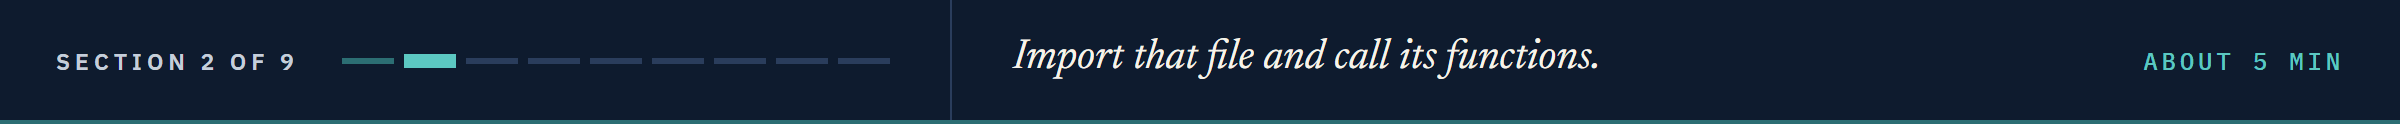

## 19.2 What a Module Is

### The File on Disk

Q. What is in `desk_tools.py`? Read it back as text.

In [4]:
# read the file back as lines of text, as in week 1's Day 2
with open('desk_tools.py') as file:
    lines = file.readlines()
print(len(lines), 'lines. The lines that start a function:')
for line in lines:
    if line.startswith('def '):
        print(line.strip())

108 lines. The lines that start a function:
def load_holdings(path: str) -> pd.DataFrame:
def clean_holdings(raw):
def check_totals(book, bonds, face, market_value):
def summarize(book):
def write_report(book, summary, path):


The file is plain text, like Day 0's `half_coupon.py`: open it in VS Code and it reads like the cell that wrote it.

### What `import` Did

`import desk_tools` found the file in this folder, ran it top to bottom, and gave the notebook one name for all of it.

Q. Which names does the module hold?

In [5]:
# week 1's Day 3 dir(); names that start with _ are Python's own
print([name for name in dir(desk_tools) if not name.startswith('_')])

['check_totals', 'clean_holdings', 'load_holdings', 'pd', 'summarize', 'write_report']


The module holds five functions and `pd`, its own import of pandas.
`desk_tools.load_holdings` is the same dot as `pd.read_csv`: pandas is a module too.

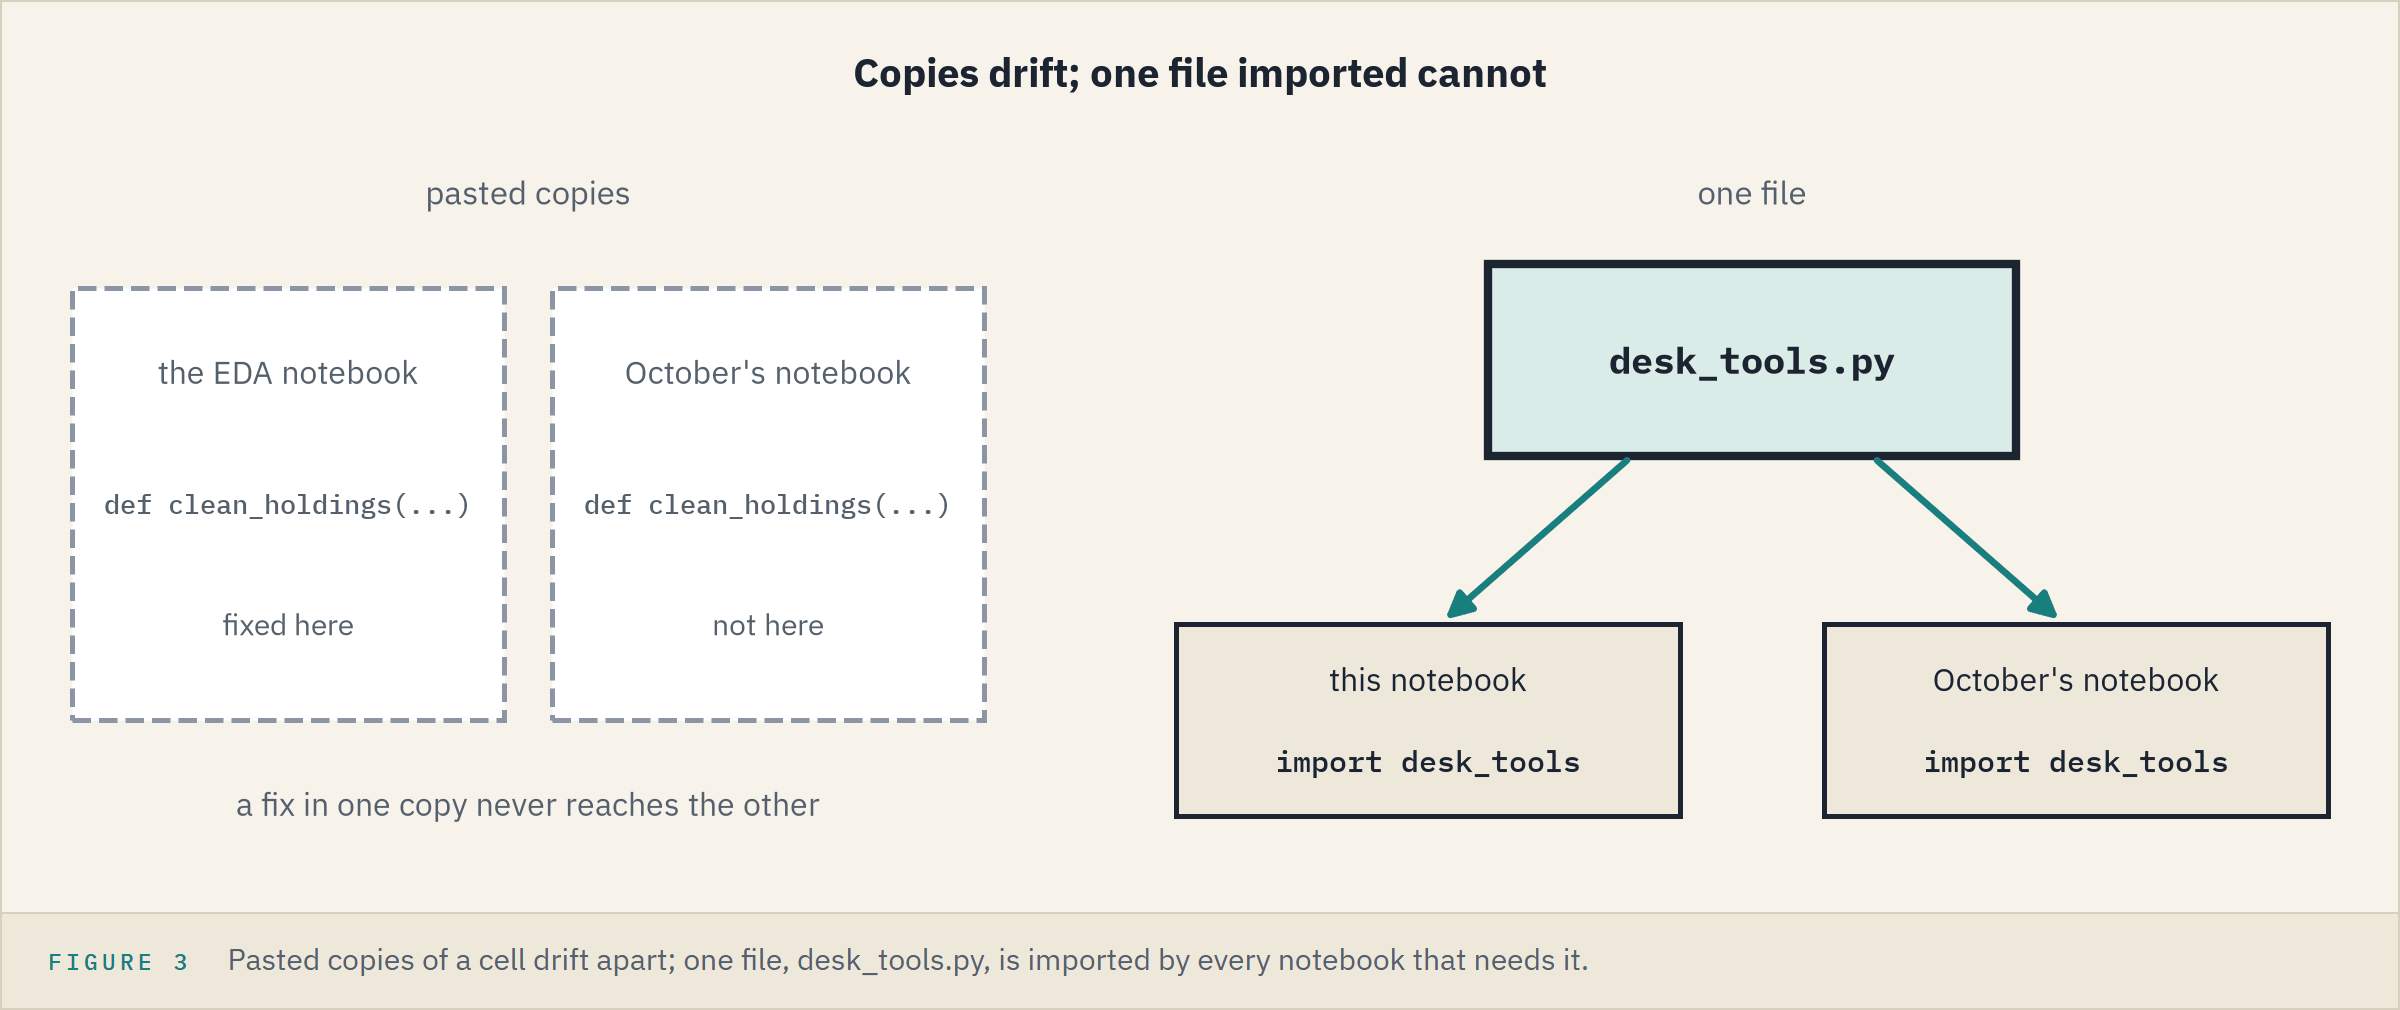

### What a Module Can See

A function in a module sees its parameters and the file's own names, never the notebook's, so the file has its own `import pandas as pd`.
A pasted copy drifts; one imported file cannot.

### Ask the Module

Q. What does `clean_holdings` do? Ask the module.

In [6]:
# week 1's Day 1 Part 2 help(), on a function of your own
help(desk_tools.clean_holdings)

Help on function clean_holdings in module desk_tools:

clean_holdings(raw)
    Apply the desk's cleaning decisions to an extract and return the cleaned table.

    The six decisions of the EDA notebook, in the same order:
      1. Exact duplicate rows are removed, keeping the first of each.
      2. Tickers are tidied: no spaces at either end, all capitals.
      3. A price dated on another day than the as-of date is flagged in a new column,
         stale_price. The price is not changed.
      4. A missing rating is labelled 'Not rated'. The bond stays in the book.
      5. A yield entered as a decimal is multiplied by 100. The test is the IQR rule:
         a yield below the first quartile less 1.5 times the IQR.
      6. Bonds with very wide spreads are real, and they are kept.

    raw is not changed. The cleaned table has one more column than raw: stale_price.



The signature, then the docstring word for word: the documentation next month's user reads, and that user is often you.

### Reading a Type Hint

Q. What does the extra part of `load_holdings`'s signature say?

In [7]:
# help() on the loader: read the line under its title
help(desk_tools.load_holdings)

Help on function load_holdings in module desk_tools:

load_holdings(path: str) -> pandas.DataFrame
    Read a holdings extract from a CSV file and return it as it arrived.

    path is the file name or the web address of the CSV. The CUSIP is read as text.



`path: str` and `-> pandas.DataFrame` are **type hints**: the type in after the colon, the type out after the arrow.
Python does not enforce them; this one is the module's only hint, there so you can read them in other people's code.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">Steps every workbook can use</td><td align="left"><code>import desk_tools</code></td><td align="left">macros in the Personal Macro Workbook, PERSONAL.XLSB, which Excel opens hidden at start-up</td></tr>
<tr><td align="left">A named function you write</td><td align="left"><code>def</code></td><td align="left"><code>=LAMBDA(oas, oas / 100)</code> named in Formulas, Name Manager, for that workbook only (Microsoft 365, Excel 2024)</td></tr>
<tr><td align="left">A function's arguments</td><td align="left"><code>help()</code></td><td align="left">type <code>=SUM</code> in a cell, then Ctrl+A: the Function Arguments box</td></tr>
</table>
<br clear="left">

**The file documents itself: what goes in, what comes out, in which unit.**

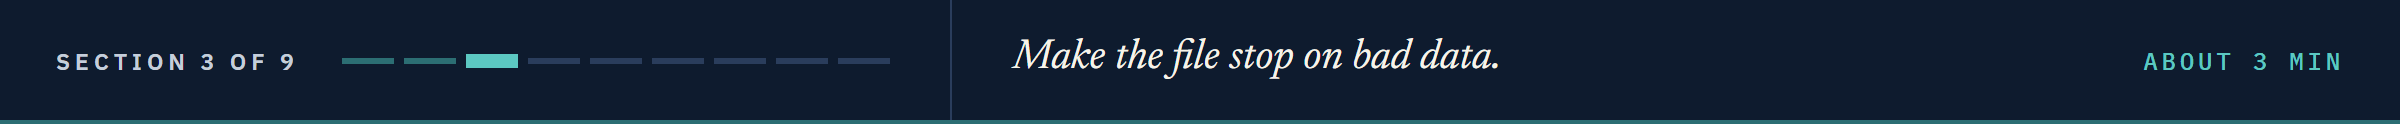

## 19.3 Checks That Stop

### The Extract As Received

Q. What does `check_totals` say about the extract as received?

In [8]:
# the extract before cleaning, against the cover note
desk_tools.check_totals(raw, expected_bonds, expected_face, expected_value)

ValueError: control totals do not match: 204 rows against 200 bonds; face of 495,500,000 against 489,000,000 dollars; market value of 497,769,925.00 against 490,819,215.00 dollars

Read from the bottom, as on week 1's Day 3: one message, three mismatches.
The lower arrow is the `raise` inside `desk_tools.py`; the upper is this notebook's call.
A printed difference can be scrolled past; an error stops Run All before a report is written.

### Still As It Arrived

Q. Did cleaning change `raw`?

In [9]:
# the EDA notebook's counts on raw: rows, repeated rows, untidy tickers, missing ratings
untidy = raw['ticker'] != raw['ticker'].str.strip().str.upper()
print(len(raw), raw.duplicated().sum(), untidy.sum(), raw['rating'].isna().sum())

204 4 8 5


Still 204, 4, 8, and 5: the function worked on a copy, so `raw` is as it arrived.

### The Headline Table

Q. What are the headline numbers of the cleaned book?

In [10]:
# the module's headline table, in pandas Part 2's Styler: separators, decimals, no row number
summary = desk_tools.summarize(book)
formats = {'face': '{:,.0f}', 'market_value': '{:,.0f}', 'mean_oas': '{:.2f}',
           'mean_yield': '{:.3f}'}
summary.style.format(formats).hide(axis='index').set_caption('The cleaned September book')

bonds,face,market_value,mean_oas,mean_yield,not_rated,stale_prices
200,"489,000,000","490,819,215",185.75,6.088,5,6


The mean OAS is 185.75 bp and the mean yield 6.088 percent, as in the EDA notebook; 5 Not rated and 6 stale prices stay open for operations.

**Excel side by side.** CUSIP in column B, face in R, market value in S; every version.

<table align="left">
<tr><th align="left">Check</th><th align="left">Excel</th></tr>
<tr><td align="left">Bonds</td><td align="left"><code>=COUNTA(B2:B201)</code></td></tr>
<tr><td align="left">Face</td><td align="left"><code>=SUM(R2:R201)</code></td></tr>
<tr><td align="left">Market value</td><td align="left"><code>=SUM(S2:S201)</code></td></tr>
<tr><td align="left">One is off</td><td align="left">the EDA notebook's <code>IF</code> cell only shows CHECK; <code>check_totals</code> stops the run</td></tr>
</table>
<br clear="left">

**The routine stops on a file that does not tie, and never changes the one it was given.**

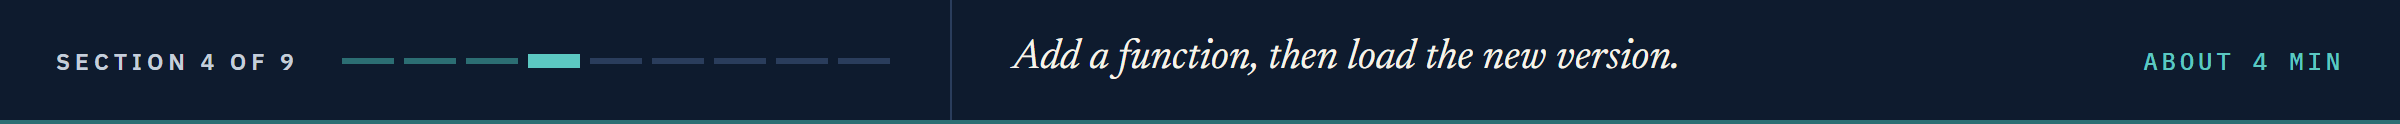

## 19.4 Edit the Module, Then Reload

The summary shows the book, not what cleaning did: the desk wants a count per decision, a sixth function.
`%%writefile -a` appends to the file, like week 1's Day 2 `'a'` mode.

### Add `count_changes`

Q. Append `count_changes(raw, book)` to the module.

In [11]:
%%writefile -a desk_tools.py


def count_changes(raw, book):
    """Count what clean_holdings changed: one row, one column for each decision.

    raw is the extract as it arrived and book is the table clean_holdings returned for it.
    """
    # the extract with its repeated rows removed lines up row for row with the cleaned book
    kept = raw.drop_duplicates().reset_index(drop=True)
    counts = {
        'rows_removed': len(raw) - len(book),
        'tickers_tidied': (kept['ticker'] != book['ticker']).sum(),
        'stale_prices_flagged': book['stale_price'].sum(),
        'ratings_labelled': kept['rating'].isna().sum(),
        'yields_corrected': (kept['yield_pct'] != book['yield_pct']).sum(),
    }
    return pd.DataFrame([counts])

Appending to desk_tools.py


### Call It Without a Reload

**Predict 1**

Q. The file now holds `count_changes`; the notebook imported `desk_tools` in 19.1. What does `desk_tools.count_changes(raw, book)` do?

A) it works: the function is in the file

B) an error: the notebook uses the module as it was imported

C) a `NameError`: `count_changes` is not defined

In [12]:
# the new function, called with no reload
desk_tools.count_changes(raw, book)

AttributeError: module 'desk_tools' has no attribute 'count_changes'

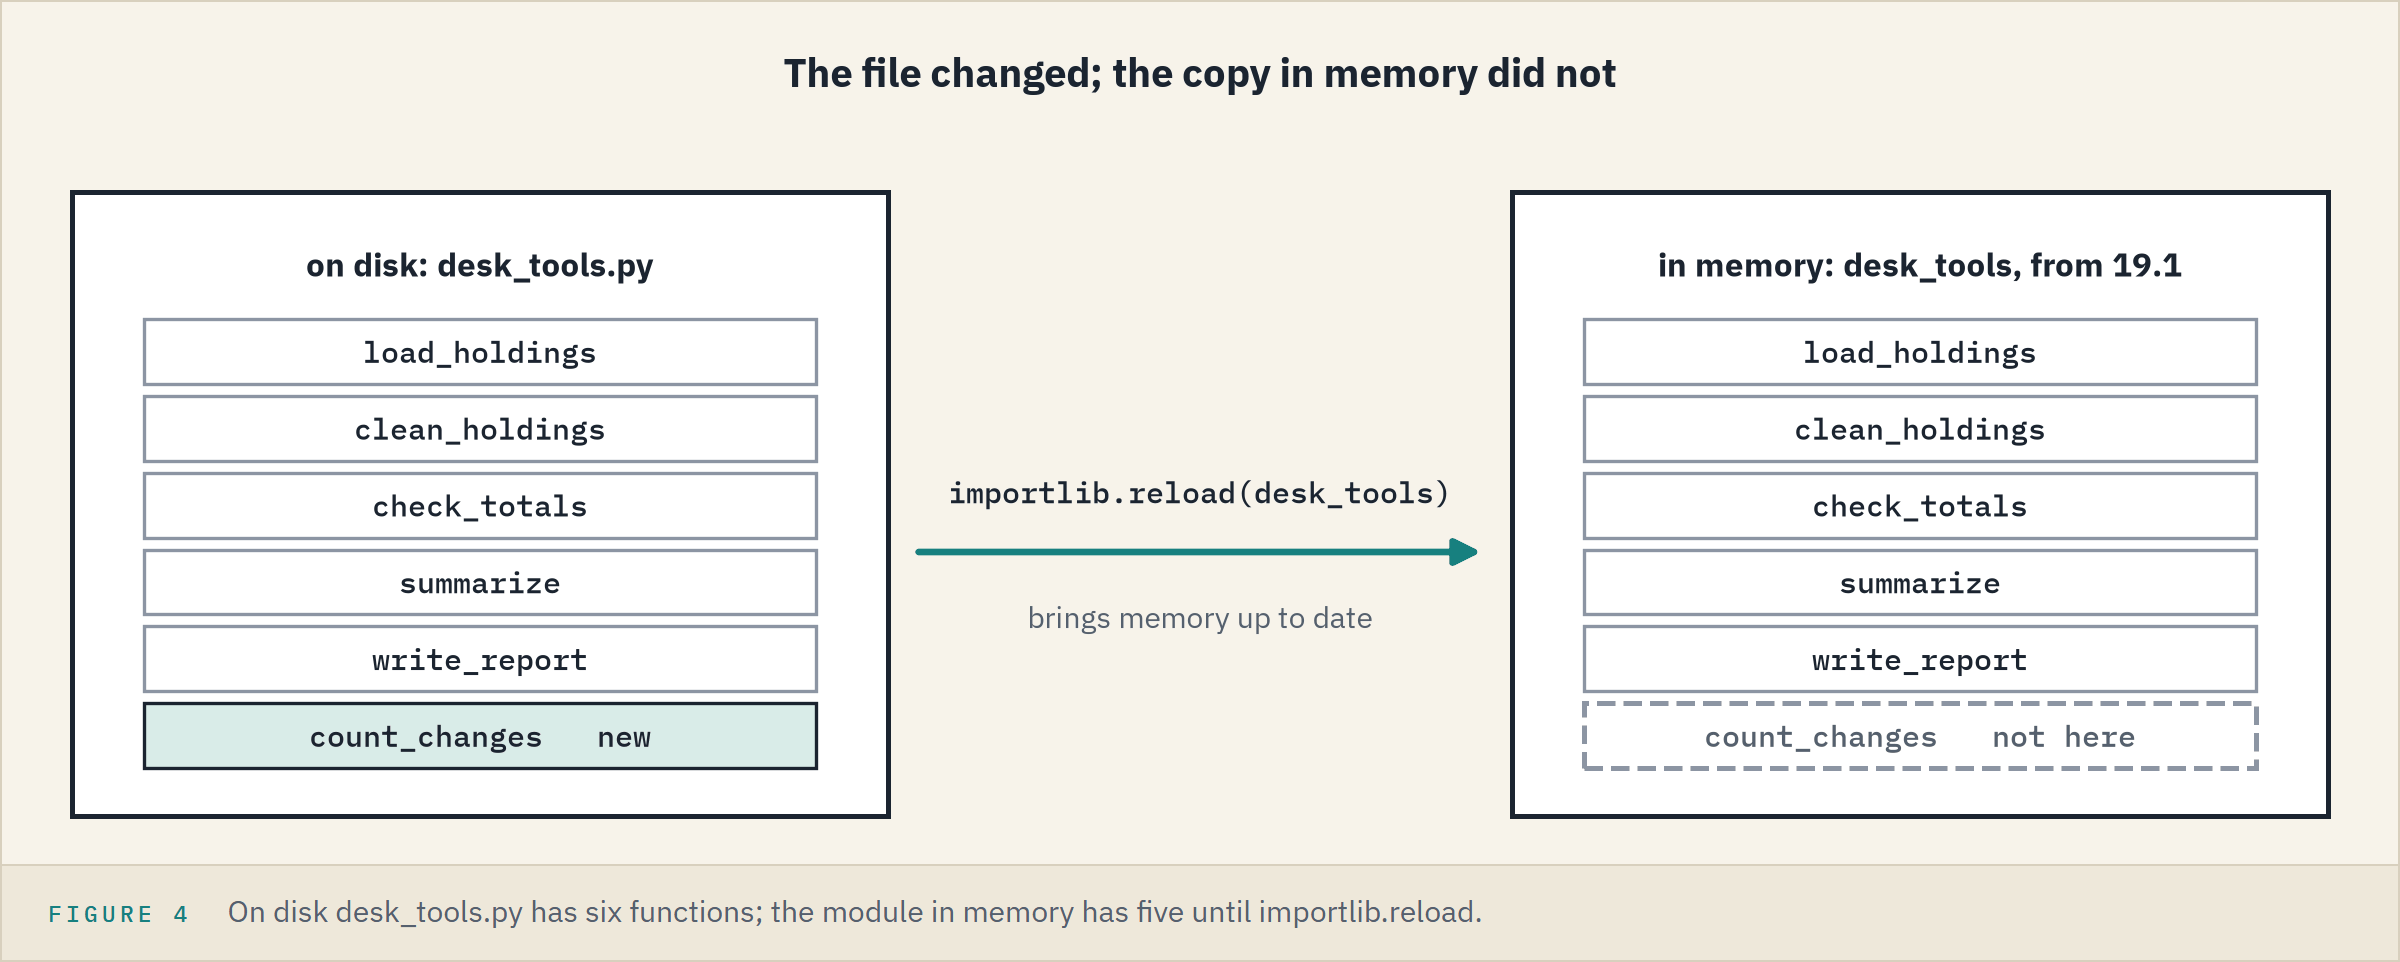

B, an `AttributeError`: `import` runs the file once and keeps a copy in memory; the edit on disk never reached it.
A second `import` does nothing either: the module is already imported.
As on Day 0, the kernel remembers what ran, not what the file now says.

### Reload and Count

Q. Reload, then count what cleaning changed in September.

In [13]:
# importlib comes with Python; reload() runs the file again and replaces the copy in memory
import importlib
importlib.reload(desk_tools)
# one count for each cleaning decision
desk_tools.count_changes(raw, book)

,rows_removed,tickers_tidied,stale_prices_flagged,ratings_labelled,yields_corrected
0,4,8,6,5,2


The counts are 4, 8, 6, 5, and 2: the EDA notebook's decision log, now counted by the module.
Edit in VS Code, save, and reload the same way; Restart and Run All is surer still.

**After every edit: reload, or restart and run from the top.**

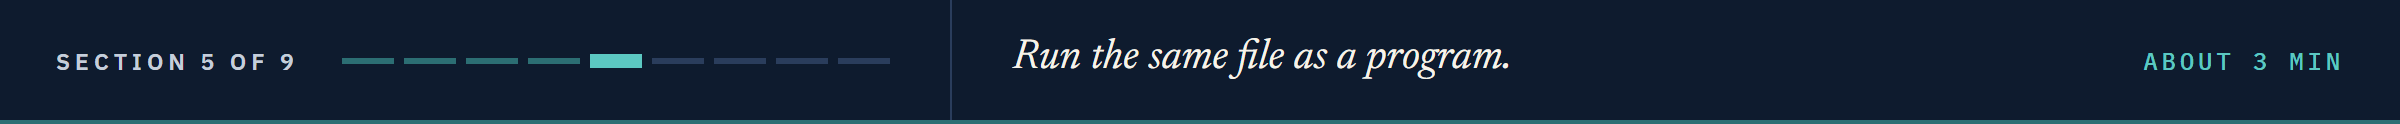

## 19.5 A Module That Is Also a Program

### Append the Block

Q. Many `.py` files end with the block below. Add it to the end of `desk_tools.py`.

In [14]:
%%writefile -a desk_tools.py


if __name__ == '__main__':
    print('desk_tools holds the month-end functions: import it to use them.')

Appending to desk_tools.py


### Reload It

**Predict 2**

Q. Reload the module with the block in it. What does the reload print?

A) the block's line: a reload runs the whole file

B) nothing

C) a `NameError`: nothing defines `__name__`

In [15]:
# reload runs the file top to bottom, as import did
importlib.reload(desk_tools)
# every module carries a name; this is the one the reload gave it
print(desk_tools.__name__)

desk_tools


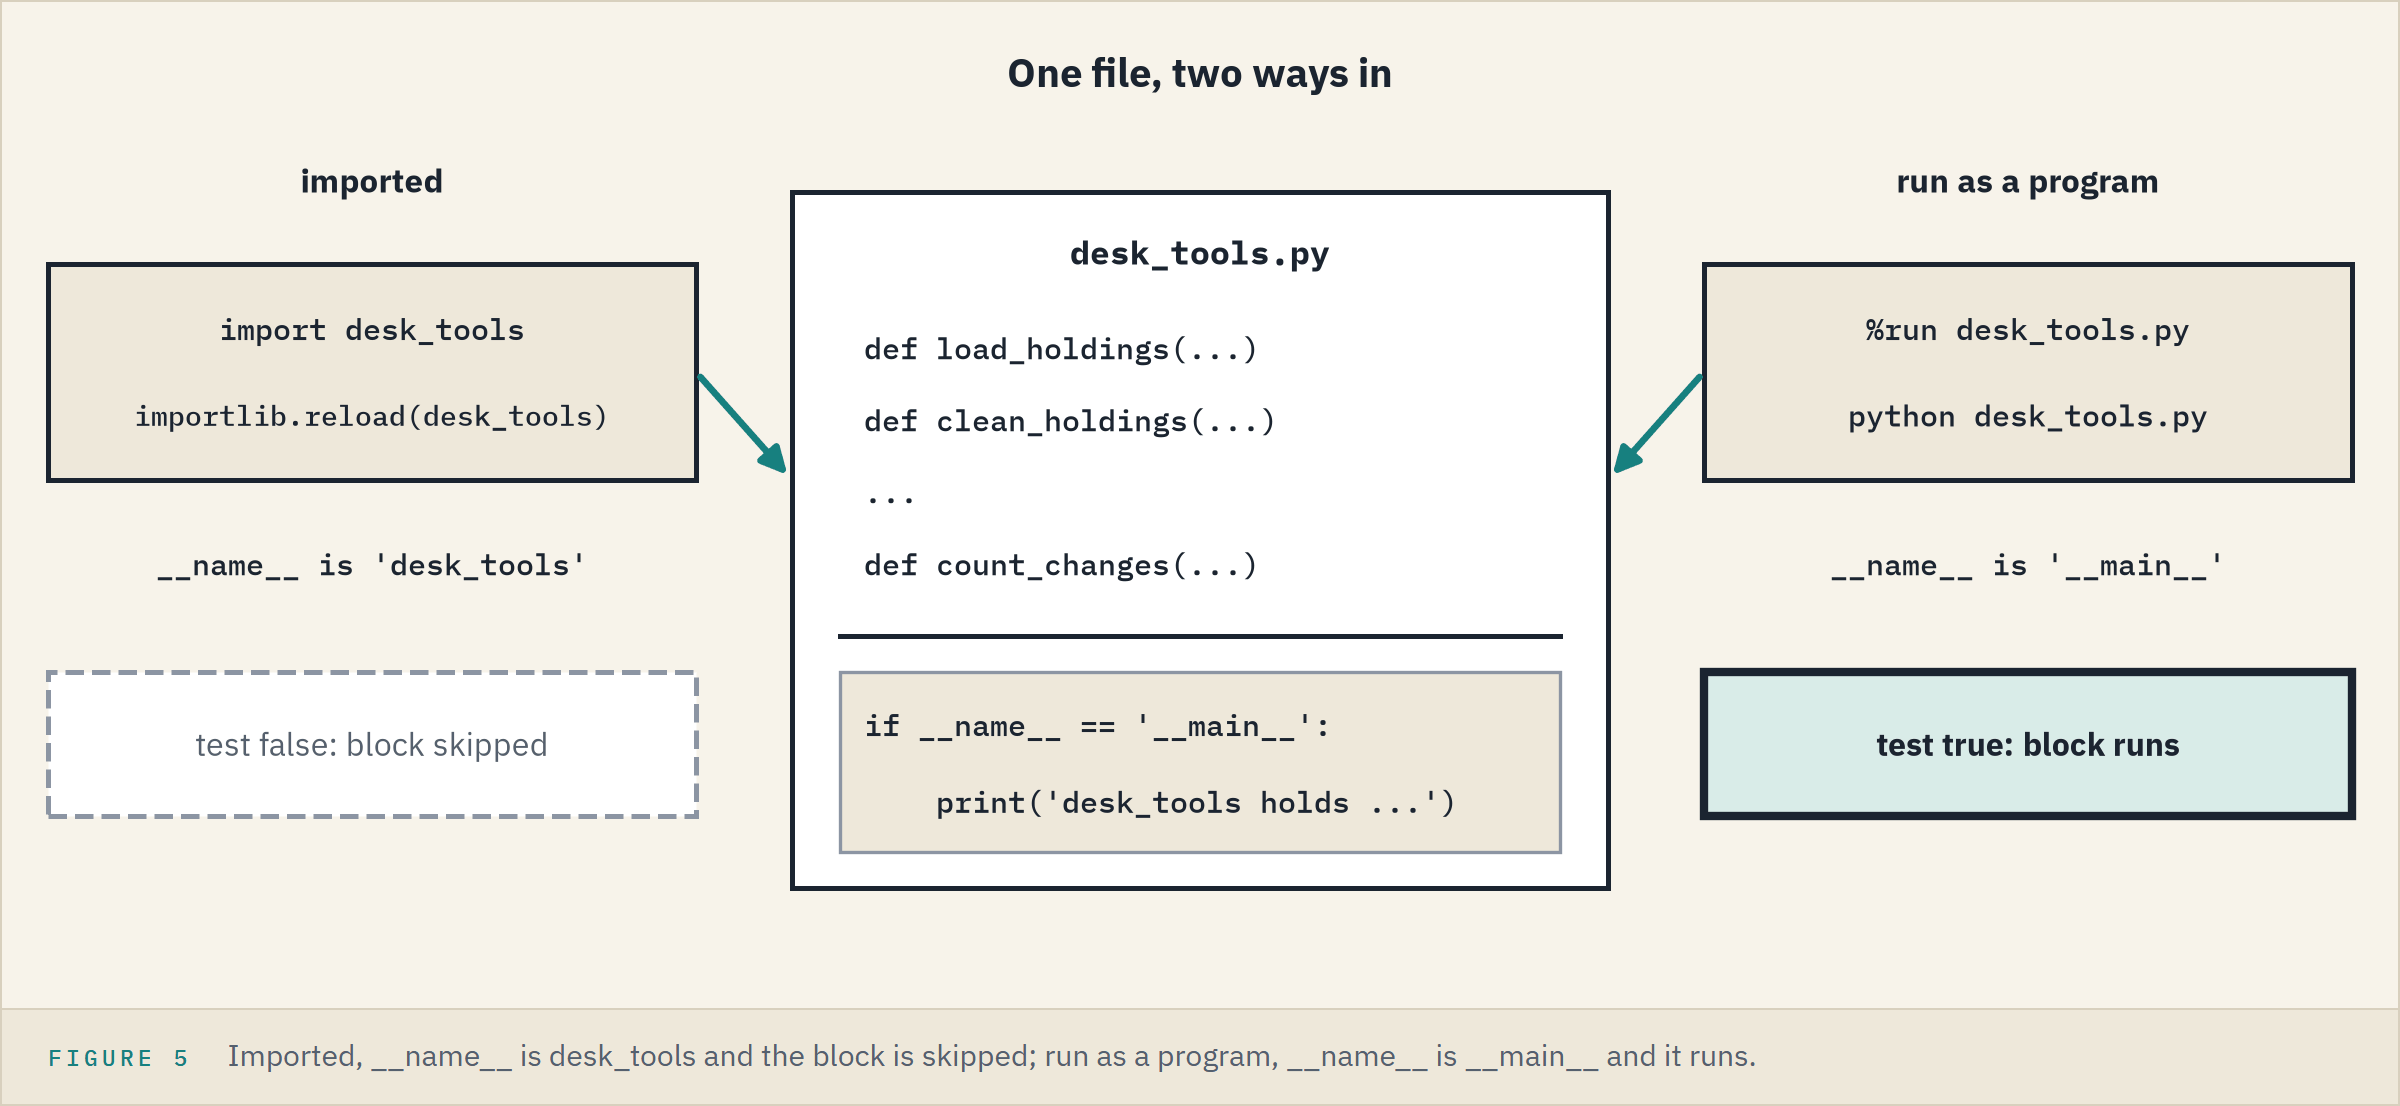

B: the reload printed nothing from the block, though the whole file ran.
Every file gets a name, `__name__`: imported or reloaded, it is `desk_tools`, so the `if` is false and the block is skipped.
Run as a program, it is `'__main__'`, week 1's Day 4 name for the program being run, and the block runs.

### Run It as a Program

Q. Run the file as a program.

In [16]:
# %run, as in Day 0, runs a .py file as a program
%run desk_tools.py

desk_tools holds the month-end functions: import it to use them.


From a terminal, as Day 0 said of `half_coupon.py`, the same is `python desk_tools.py`.

**Above the line, a module to import; below it, what the file does when run.**

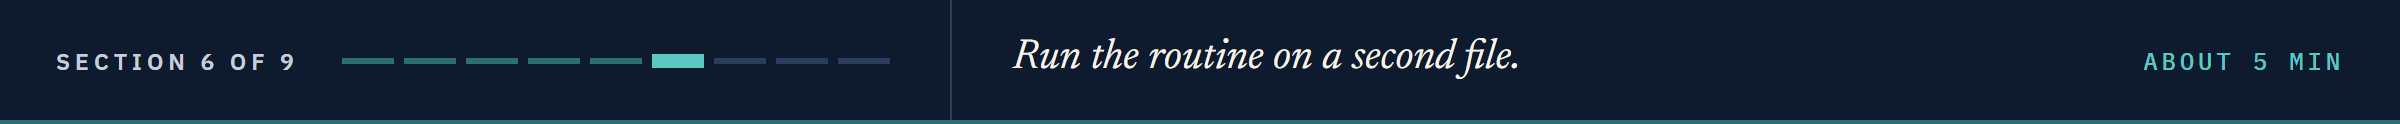

## 19.6 The Same Lines on a Second File

The point of a module: the same lines on another file.
A routine safe to keep fixes the file with problems and leaves `holdings.csv` alone.

### Each File As Received

Q. Does each file, as received, match the cover note?

In [17]:
# the two September files, each checked against the cover note as it arrived
files = ['holdings_messy.csv', 'holdings.csv']
for file in files:
    received = desk_tools.load_holdings(data_folder + file)
    # week 1's Day 3 try and except: report the error, then go on to the next file
    try:
        desk_tools.check_totals(received, expected_bonds, expected_face, expected_value)
        print(file, 'matches the cover note as received')
    except ValueError as error:
        print(file, error)

holdings_messy.csv control totals do not match: 204 rows against 200 bonds; face of 495,500,000 against 489,000,000 dollars; market value of 497,769,925.00 against 490,819,215.00 dollars
holdings.csv matches the cover note as received


Catch an error to report it, as here; the run below catches nothing, so a table that does not tie stops it.

### The Clean File's Counts

**Predict 3**

Q. Both files go through the same lines. Add the five `count_changes` counts for `holdings.csv`: what total? Write down a number; some expect the IQR rule to move a yield or two.

### Both Files Through the Routine

In [18]:
# each file's results, kept under its file name
books = {}
summaries = {}
changes = {}
for file in files:
    received = desk_tools.load_holdings(data_folder + file)
    books[file] = desk_tools.clean_holdings(received)
    desk_tools.check_totals(books[file], expected_bonds, expected_face, expected_value)
    summaries[file] = desk_tools.summarize(books[file])
    # the one row of counts, as a Series
    changes[file] = desk_tools.count_changes(received, books[file]).iloc[0]

In [19]:
# a dictionary of Series becomes a table, decisions down and files across (Combining Part 2)
all_changes = pd.DataFrame(changes)
all_changes

,holdings_messy.csv,holdings.csv
rows_removed,4,0
tickers_tidied,8,0
stale_prices_flagged,6,0
ratings_labelled,5,0
yields_corrected,2,0


The total is 0: five zeros for `holdings.csv`, and both cleaned tables tied.

### Why No Clean Yield Moved

Q. Where is the IQR rule's lower limit on the clean file, and where is its lowest yield?

In [20]:
# the EDA notebook's IQR rule, on the clean file's yields in percent
clean_yields = books['holdings.csv']['yield_pct']
q1, q3 = clean_yields.quantile(0.25), clean_yields.quantile(0.75)
print(round(q1 - 1.5 * (q3 - q1), 3), clean_yields.min())

3.055 4.089


Nothing sits below 3.055, so nothing is multiplied; a false flag would make a real yield 100 times too large.

### What Changed, Drawn

Q. Draw the counts, one group of bars for each decision.

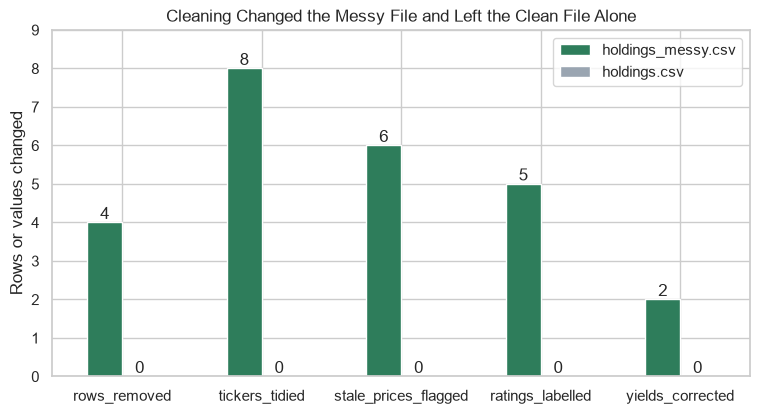

In [21]:
# pandas' .plot.bar takes ax= as seaborn does: one group per row, one bar per file
fig, ax = plt.subplots(figsize=(9, 4.5))
all_changes.plot.bar(ax=ax, rot=0)
for container in ax.containers:
    ax.bar_label(container)
ax.set_title('Cleaning Changed the Messy File and Left the Clean File Alone')
ax.set_ylabel('Rows or values changed')
# More Visualization's set_ylim(): room above the tallest bar for its label
ax.set_ylim(0, 9)
plt.show()

The green bars are the messy file; the grey ones, the clean file, stand at 0 on every decision.

### Two Books, Side by Side

Q. Do the two cleaned books agree?

In [22]:
# the two headline tables, one above the other (Combining Part 1's concat)
both = pd.concat([summaries[file] for file in files], ignore_index=True)
both.style.format(formats).set_caption('Row 0: the messy file cleaned. Row 1: the clean file.')

,bonds,face,market_value,mean_oas,mean_yield,not_rated,stale_prices
0,200,"489,000,000","490,819,215",185.75,6.088,5,6
1,200,"489,000,000","490,819,215",185.75,6.088,0,0


Five figures match; only the open items differ, 5 and 6 against 0 and 0.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">Next month's file</td><td align="left">change the file name</td><td align="left">re-point every range: <code>S2:S205</code> on the 204-row extract, <code>S2:S201</code> on the 200-row file</td></tr>
<tr><td align="left">Same steps, new source</td><td align="left">the loop above</td><td align="left">Power Query: Data, Get Data, Data Source Settings, Change Source, then Refresh (Excel 2016 and later)</td></tr>
</table>
<br clear="left">

**One file name changed, and the clean file came through untouched.**

> STORY: In 2013 Thomas Herndon, Michael Ash and Robert Pollin checked the working spreadsheet behind Reinhart and Rogoff's 2010 paper "Growth in a Time of Debt" and found an average whose range stopped short, leaving five countries out: Australia, Austria, Belgium, Canada, and Denmark. Sources: PERI Working Paper 322, April 2013, https://peri.umass.edu/publication/does-high-public-debt-consistently-stifle-economic-growth-a-critique-of-reinhart-and-rogoff/; Cambridge Journal of Economics 38(2), 257-279, 2014, https://doi.org/10.1093/cje/bet075. A range does not move when the rows do.

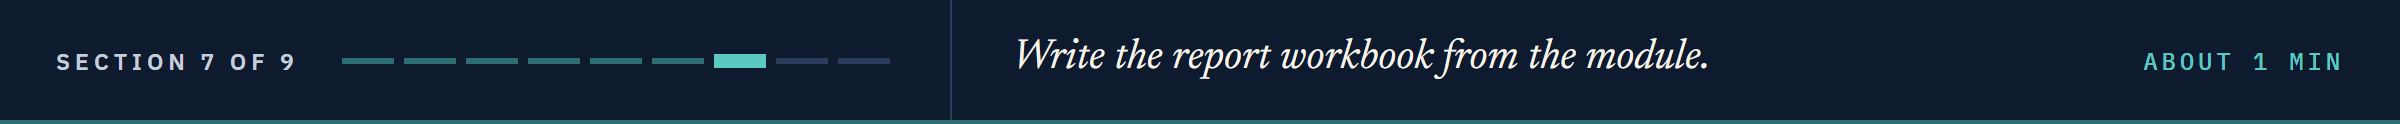

## 19.7 The Report Workbook

The PM reads Excel: `write_report` writes two sheets with Combining Part 2's `pd.ExcelWriter`.

### Write It, Read It Back

Q. Write the September report and read both sheets back. Does the book sheet still tie?

In [23]:
# write the September workbook with the module, then read both sheets back
report_file = 'month_end_report.xlsx'
desk_tools.write_report(book, summary, report_file)
summary_back = pd.read_excel(report_file, sheet_name='summary')
book_back = pd.read_excel(report_file, sheet_name='book', dtype={'cusip': str})
# the sheet as read back, against the cover note
desk_tools.check_totals(book_back, expected_bonds, expected_face, expected_value)
print(summary_back.shape, book_back.shape)
# a desk keeps and sends the report; the course removes what it writes
os.remove(report_file)

(1, 7) (200, 20)


`check_totals` raised nothing on the sheet read back: a function does not care where its table came from.
The workbook holds values, not formulas.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">Two tables, one file</td><td align="left"><code>pd.ExcelWriter</code>, one <code>to_excel(sheet_name=)</code> each</td><td align="left">one workbook, two sheets</td></tr>
<tr><td align="left">Totals of the sheet</td><td align="left"><code>check_totals(book_back, ...)</code></td><td align="left"><code>=COUNTA(book!B2:B201)</code>, <code>=SUM(book!R2:R201)</code>, <code>=SUM(book!S2:S201)</code></td></tr>
</table>
<br clear="left">

**The PM's workbook still ties after the round trip.**

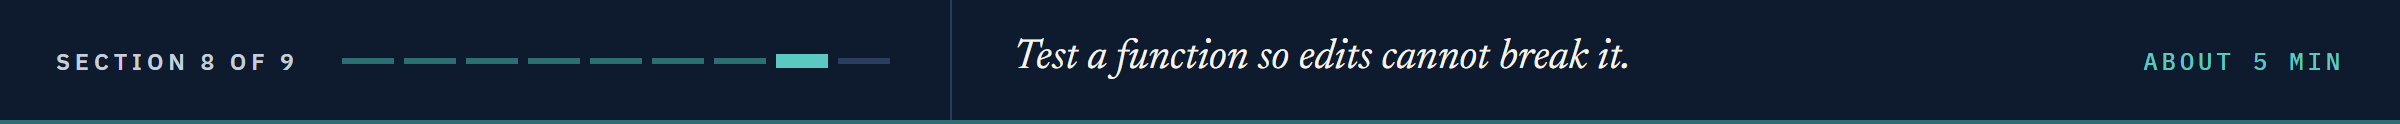

## 19.8 Testing a Function

The totals test a run; a **test** checks the function itself, on a table small enough to work by hand.
Break the ticker step next year and the totals still tie; a test on tickers fails.

### A Table Small Enough to Work by Hand

Q. Type seven rows holding one of each problem.

In [24]:
# made-up CUSIPs and figures, in the six columns clean_holdings reads; None is a missing rating
tiny = pd.DataFrame({
    'cusip': ['TEST00001', 'TEST00002', 'TEST00003', 'TEST00004', 'TEST00005',
              'TEST00006', 'TEST00006'],
    'ticker': ['KRIX', ' krix', 'MORX', 'MORX', 'THAA', 'CORA', 'CORA'],
    'rating': ['BBB', 'BBB', None, 'A', 'BB', 'B', 'B'],
    'yield_pct': [5.1, 6.2, 5.5, 4.9, 0.0575, 5.8, 5.8],
    # a list times 7 is that list repeated seven times: one as-of date per row
    'as_of_date': ['2026-09-30'] * 7,
    'price_date': ['2026-09-30', '2026-09-30', '2026-09-30', '2026-08-14', '2026-09-30',
                   '2026-09-30', '2026-09-30'],
})
tiny

,cusip,ticker,rating,yield_pct,as_of_date,price_date
0,TEST00001,KRIX,BBB,5.1000,2026-09-30,2026-09-30
1,TEST00002,krix,BBB,6.2000,2026-09-30,2026-09-30
2,TEST00003,MORX,NaN,5.5000,2026-09-30,2026-09-30
3,TEST00004,MORX,A,4.9000,2026-09-30,2026-08-14
4,TEST00005,THAA,BB,0.0575,2026-09-30,2026-09-30
5,TEST00006,CORA,B,5.8000,2026-09-30,2026-09-30
6,TEST00006,CORA,B,5.8000,2026-09-30,2026-09-30


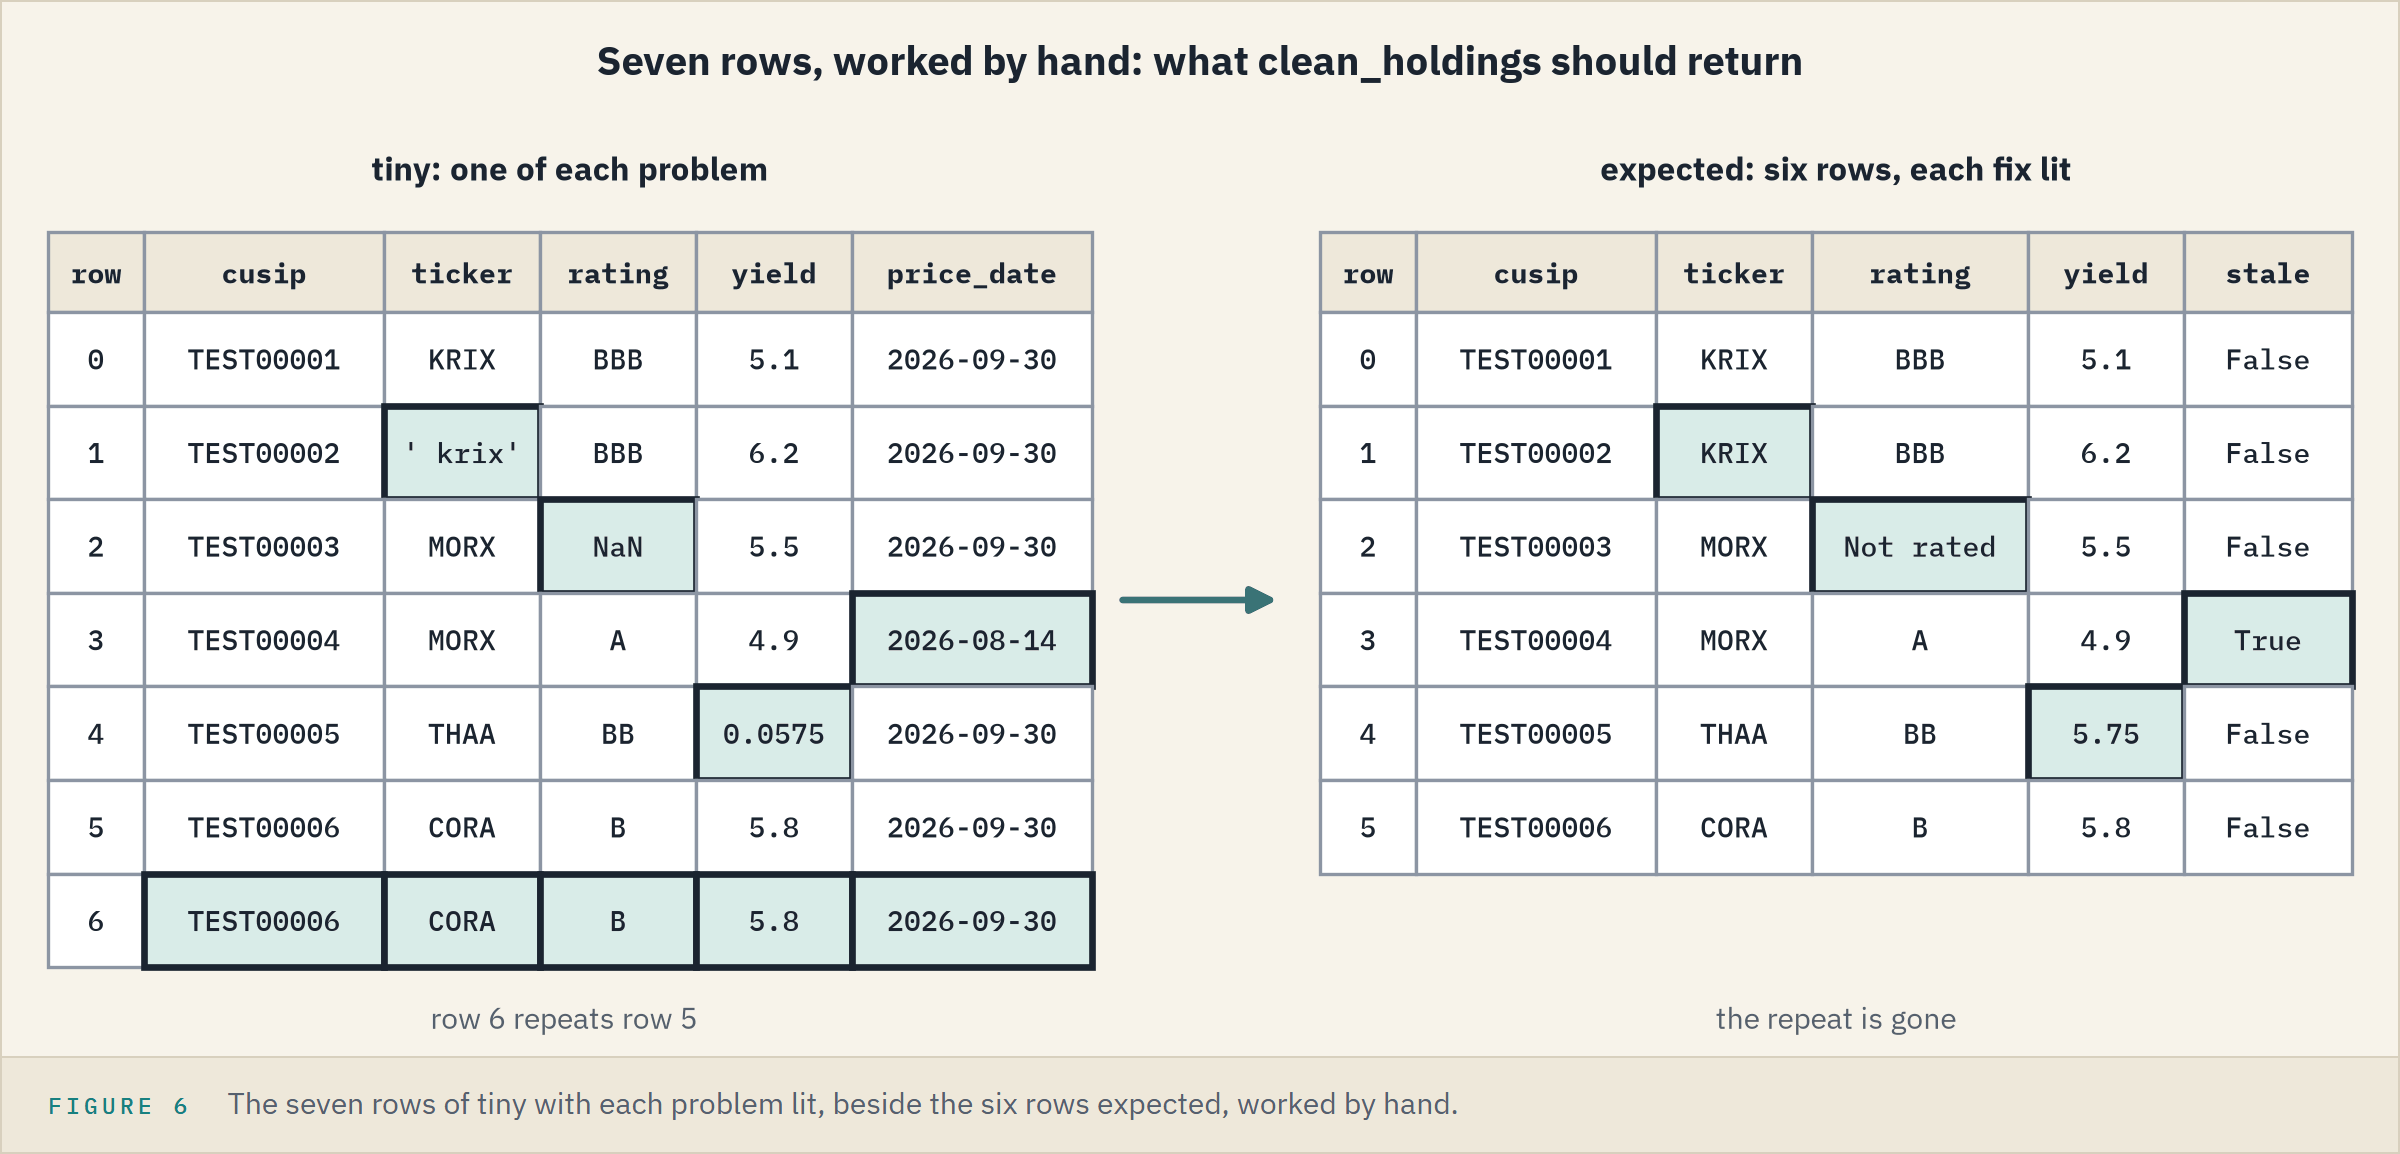

Worked by hand, the answer is six rows: ` krix` tidied, row 2 Not rated, 0.0575 made 5.75, and row 3 flagged stale.

### Three Tests That Pass

Q. Clean `tiny`. Is the repeat gone, and is `tiny` untouched?

In [25]:
# clean the seven rows; an assert that passes prints nothing (week 1's Day 3), so the print says so
tidy = desk_tools.clean_holdings(tiny)
assert len(tidy) == 6, f'expected 6 rows, found {len(tidy)}'
# the First Look case study's is_unique: every CUSIP once
assert tidy['cusip'].is_unique, 'a CUSIP is still repeated'
# the docstring's promise: the table passed in is not changed
assert len(tiny) == 7, 'the table passed in was changed'
print('Test 1 passed:', len(tiny), 'rows in,', len(tidy), 'out')

Test 1 passed: 7 rows in, 6 out


Q. Test the tickers and the yields.

In [26]:
# the tickers worked by hand: spaces gone, all capitals, the repeat gone
expected_tickers = ['KRIX', 'KRIX', 'MORX', 'MORX', 'THAA', 'CORA']
assert tidy['ticker'].tolist() == expected_tickers, f"tickers are {tidy['ticker'].tolist()}"
print('Test 2 passed:', tidy['ticker'].tolist())
# the decimal corrected, and the five right yields untouched
assert tidy['yield_pct'].tolist() == [5.1, 6.2, 5.5, 4.9, 5.75, 5.8], 'another yield moved'
print('Test 3 passed:', tidy['yield_pct'].tolist())

Test 2 passed: ['KRIX', 'KRIX', 'MORX', 'MORX', 'THAA', 'CORA']
Test 3 passed: [5.1, 6.2, 5.5, 4.9, 5.75, 5.8]


The yield test has two halves: fix the wrong yield and leave the right ones alone.
The IQR rule needs a few rows to work, hence six bonds, not two.

### A Test That Fails

A colleague remembers the label as `NR`.

Q. What does a failing test look like?

In [27]:
# the label the colleague expects
assert tidy.loc[2, 'rating'] == 'NR', f"expected the label NR, found {tidy.loc[2, 'rating']}"
print('Test 4 passed')

AssertionError: expected the label NR, found Not rated

The docstring settles it: decision 4's label is `Not rated`, so the test is wrong.
On another day it is the function; the message names the value found either way.

### Every Test in One Function

Q. Put the passing checks in one function, so one line runs them all.

In [28]:
def test_clean_holdings():
    # the five checks, on the tiny table worked by hand
    result = desk_tools.clean_holdings(tiny)
    assert len(result) == 6, f'expected 6 rows, found {len(result)}'
    assert result['ticker'].tolist() == expected_tickers, 'tickers not tidied'
    assert result.loc[2, 'rating'] == 'Not rated', 'missing rating not labelled'
    assert result['yield_pct'].tolist() == [5.1, 6.2, 5.5, 4.9, 5.75, 5.8], 'yields wrong'
    assert result['stale_price'].tolist() == [False, False, False, True, False, False], 'stale'
    print('clean_holdings: 5 checks passed')


test_clean_holdings()

clean_holdings: 5 checks passed


Run it after every reload.
`pytest`, a tool you will meet, runs every function whose name starts with `test_`, with one command.

**Excel side by side.** A sheet of made-up rows with known answers, where a formula is tried before it meets 200 real rows.

**A test fails loudly where the totals stay silent.**

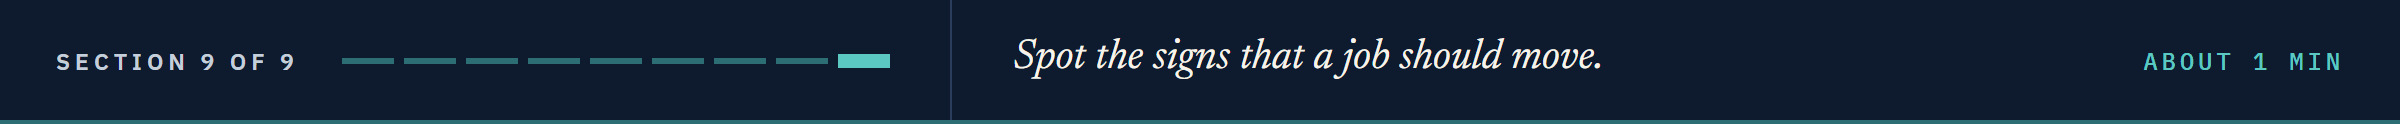

## 19.9 Which Jobs to Move

A module costs time to write and test, and pays it back only when work repeats.

Stay in the spreadsheet for a one-off look, a table someone edits by hand, a job with no next month, or twenty rows you can check by eye.

Move a job when it shows the signs:

<table align="left">
<tr><th align="left">Sign</th><th align="left">September's routine</th></tr>
<tr><td align="left">It repeats</td><td align="left">every month end</td></tr>
<tr><td align="left">The input changes shape</td><td align="left">204 rows, then 200</td></tr>
<tr><td align="left">It has control totals</td><td align="left">the cover note's three</td></tr>
<tr><td align="left">Others rely on it</td><td align="left">the PM's workbook</td></tr>
<tr><td align="left">The steps are hard to see</td><td align="left">six decisions, now in one docstring</td></tr>
</table>
<br clear="left">

**Move a job when it repeats, changes shape, has control totals, feeds others, and hides its steps.**

## You Can Now

By the end of this notebook, you can:

* Write a module with `%%writefile`, and append with `%%writefile -a`.
* Import it, and read it with `dir()` and `help()`.
* Reload it after an edit, and say why.
* Read `if __name__ == '__main__':`, and run a file with `%run`.
* Run the same lines on a second file, and count each decision's changes.
* Write a two-sheet workbook, read it back, and check it.
* Test a function on a table worked by hand.
* Say which jobs belong in a module.

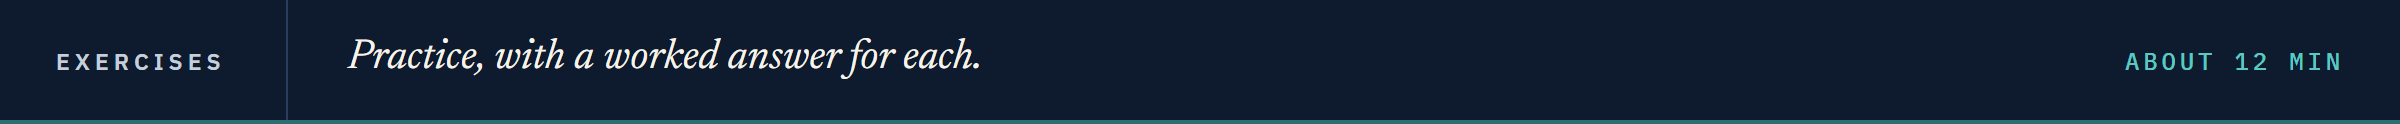

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell under it.
Run the next three cells first: the module without its program block, `check`, and the loader.

In [29]:
%%writefile desk_tools.py
"""Desk tools: load, clean, check, summarize, and report a month-end holdings extract.

From Python for Fixed Income, Course 1, From Notebook to Module. All data is synthetic.
"""
import pandas as pd


def load_holdings(path: str) -> pd.DataFrame:
    """Read a holdings extract from a CSV file and return it as it arrived.

    path is the file name or the web address of the CSV. The CUSIP is read as text.
    """
    return pd.read_csv(path, dtype={'cusip': str})


def clean_holdings(raw):
    """Apply the desk's cleaning decisions to an extract and return the cleaned table.

    The six decisions of the EDA notebook, in the same order:
      1. Exact duplicate rows are removed, keeping the first of each.
      2. Tickers are tidied: no spaces at either end, all capitals.
      3. A price dated on another day than the as-of date is flagged in a new column,
         stale_price. The price is not changed.
      4. A missing rating is labelled 'Not rated'. The bond stays in the book.
      5. A yield entered as a decimal is multiplied by 100. The test is the IQR rule:
         a yield below the first quartile less 1.5 times the IQR.
      6. Bonds with very wide spreads are real, and they are kept.

    raw is not changed. The cleaned table has one more column than raw: stale_price.
    """
    # work in a copy, so that the table passed in stays as it arrived
    book = raw.copy()

    # decision 1: remove the repeated rows and renumber the rows from 0
    book = book.drop_duplicates().reset_index(drop=True)

    # decision 2: tidy the tickers
    book['ticker'] = book['ticker'].str.strip().str.upper()

    # decision 3: flag the stale prices, and leave them as they are
    book['stale_price'] = book['price_date'] != book['as_of_date']

    # decision 4: label the missing ratings
    book['rating'] = book['rating'].fillna('Not rated')

    # decision 5: yields in percent, where one was entered as a decimal
    q1 = book['yield_pct'].quantile(0.25)
    q3 = book['yield_pct'].quantile(0.75)
    lower_limit = q1 - 1.5 * (q3 - q1)
    entered_as_decimal = book['yield_pct'] < lower_limit
    book.loc[entered_as_decimal, 'yield_pct'] = (
        book.loc[entered_as_decimal, 'yield_pct'] * 100).round(3)

    # decision 6: the very wide bonds are real and they stay, so there is no line for them

    return book


def check_totals(book, bonds, face, market_value):
    """Test a table against its three control totals. Raise ValueError if any one does not match.

    bonds is the number of rows the table should have. face and market_value are in dollars.
    Nothing is returned: if the function finishes without an error, the table matches.
    """
    found_bonds = len(book)
    found_face = book['par_held'].sum()
    found_value = book['market_value'].sum()

    # collect every mismatch, so that one message reports them all
    problems = []
    if found_bonds != bonds:
        problems.append(f'{found_bonds:,} rows against {bonds:,} bonds')
    if found_face != face:
        problems.append(f'face of {found_face:,} against {face:,} dollars')
    # market value has cents, so allow half a cent for decimal arithmetic
    if abs(found_value - market_value) > 0.005:
        problems.append(f'market value of {found_value:,.2f} against {market_value:,.2f} dollars')

    if problems:
        raise ValueError('control totals do not match: ' + '; '.join(problems))


def summarize(book):
    """Return the headline table of a cleaned book: one row, one column for each figure.

    face and market_value are in dollars, mean_oas in basis points, mean_yield in percent.
    not_rated and stale_prices count the bonds that clean_holdings labelled or flagged.
    """
    headline = {
        'bonds': len(book),
        'face': book['par_held'].sum(),
        'market_value': book['market_value'].sum(),
        'mean_oas': round(book['oas'].mean(), 2),
        'mean_yield': round(book['yield_pct'].mean(), 3),
        'not_rated': (book['rating'] == 'Not rated').sum(),
        'stale_prices': book['stale_price'].sum(),
    }
    # a list holding one dictionary becomes a table with one row
    return pd.DataFrame([headline])


def write_report(book, summary, path):
    """Write the month-end workbook to path: the headline table on a sheet named 'summary'
    and the cleaned book on a sheet named 'book'.
    """
    with pd.ExcelWriter(path) as writer:
        summary.to_excel(writer, sheet_name='summary', index=False)
        book.to_excel(writer, sheet_name='book', index=False)


def count_changes(raw, book):
    """Count what clean_holdings changed: one row, one column for each decision.

    raw is the extract as it arrived and book is the table clean_holdings returned for it.
    """
    # the extract with its repeated rows removed lines up row for row with the cleaned book
    kept = raw.drop_duplicates().reset_index(drop=True)
    counts = {
        'rows_removed': len(raw) - len(book),
        'tickers_tidied': (kept['ticker'] != book['ticker']).sum(),
        'stale_prices_flagged': book['stale_price'].sum(),
        'ratings_labelled': kept['rating'].isna().sum(),
        'yields_corrected': (kept['yield_pct'] != book['yield_pct']).sum(),
    }
    return pd.DataFrame([counts])

Overwriting desk_tools.py


In [30]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [31]:
import importlib
import os
import sys

import pandas as pd

# no __pycache__ folder, as in the lesson
sys.dont_write_bytecode = True
# import the module the cell above wrote; reload() makes sure this is that version
import desk_tools
importlib.reload(desk_tools)
if os.path.exists('../../../data/holdings_messy.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
expected_bonds = 200
expected_face = 489_000_000
expected_value = 490_819_215
raw = desk_tools.load_holdings(data_folder + 'holdings_messy.csv')
book = desk_tools.clean_holdings(raw)
desk_tools.check_totals(book, expected_bonds, expected_face, expected_value)
print(raw.shape, book.shape)

(204, 19) (200, 20)


### Exercise 1

Q. Add `sector_totals(book)` to the module, with a docstring: each sector's market value in dollars, as a Series sorted largest first.
Write it in the next cell and run that cell once; reload, then store the largest sector in **ex1_sector** and its market value in **ex1_value**.

In [32]:
%%writefile -a desk_tools.py


# Exercise 1: write sector_totals(book) below this line

Appending to desk_tools.py


In [33]:
# reload the module, then call your function on book
ex1_sector = ...
ex1_value = ...

In [34]:
check('Exercise 1 largest sector', ex1_sector, 'Materials')
check('Exercise 1 market value', ex1_value, 71701617.5)

Exercise 1 largest sector: not attempted yet
Exercise 1 market value: not attempted yet


### Exercise 2

Q. Write `check_unique(table, column)`: nothing happens when no value of `column` repeats, otherwise it raises `ValueError` with the message `N repeated values in COLUMN`.
Call it on `book` and `'cusip'`, then on `raw` inside `try` and `except`; store `str(error)` in **ex2_message**.

In [35]:
# define check_unique(table, column), call it on book, then on raw inside try and except
ex2_message = ...

In [36]:
check('Exercise 2 message', ex2_message, '4 repeated values in cusip')

Exercise 2 message: not attempted yet


### Exercise 3

Q. With the module, load, clean, check, and summarize `holdings.csv`, write `exercise_report.xlsx`, read both sheets back, and delete the workbook.
Store the book sheet's rows in **ex3_rows**, the summary's mean yield in percent in **ex3_yield** and its stale prices in **ex3_stale**, and whether the workbook still exists in **ex3_left**.

In [37]:
ex3_rows = ...
ex3_yield = ...
ex3_stale = ...
ex3_left = ...

In [38]:
check('Exercise 3 rows on the book sheet', ex3_rows, 200)
check('Exercise 3 mean yield', ex3_yield, 6.088)
check('Exercise 3 stale prices', ex3_stale, 0)
check('Exercise 3 workbook left behind', ex3_left, False)

Exercise 3 rows on the book sheet: not attempted yet
Exercise 3 mean yield: not attempted yet
Exercise 3 stale prices: not attempted yet
Exercise 3 workbook left behind: not attempted yet


### Exercise 4: AI check

The function below, written for this course in the style of an AI assistant's answer, weights OAS by market value and holds one bug.

Q. Work out the weighted OAS of `two_bonds` by hand, then run the cell. Write an `assert` with your answer, and fix the function until it passes.

In [39]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
def weighted_mean_oas(book):
    """Return the average OAS of a book in basis points, weighted by market value."""
    # weight each bond's OAS by its size
    weighted_sum = (book['oas'] * book['par_held']).sum()
    return weighted_sum / book['par_held'].sum()


# a test table: two bonds with the same market value
two_bonds = pd.DataFrame({'oas': [900, 100], 'par_held': [2_000_000, 1_000_000],
                          'market_value': [1_000_000.0, 1_000_000.0]})
ex4_two_bonds = round(weighted_mean_oas(two_bonds), 2)
ex4_book = round(weighted_mean_oas(book), 2)
print(ex4_two_bonds, ex4_book)

633.33 184.52


In [40]:
check('Exercise 4 two bonds', ex4_two_bonds, 500.0)
check('Exercise 4 the book', ex4_book, 180.46)

Exercise 4 two bonds: not yet. You have 633.33
Exercise 4 the book: not yet. You have 184.52


### Tidying Up

The last cell deletes `desk_tools.py`, as the course removes what it writes; on a desk you would keep it.

In [41]:
# delete every file this notebook wrote, if it is still there
for file in ['desk_tools.py', 'month_end_report.xlsx', 'exercise_report.xlsx']:
    if os.path.exists(file):
        os.remove(file)
    print(file, os.path.exists(file))

desk_tools.py False
month_end_report.xlsx False
exercise_report.xlsx False


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">One file</td><td align="left"><code>desk_tools.py</code>, six functions, imported</td></tr>
<tr><td align="left">Tie the cover note</td><td align="left">200 bonds, 490,819,215.00 dollars</td></tr>
<tr><td align="left">Count the changes</td><td align="left">4, 8, 6, 5, and 2</td></tr>
<tr><td align="left">Leave a clean file alone</td><td align="left">five zeros</td></tr>
<tr><td align="left">The workbook</td><td align="left">two sheets, tied after the round trip</td></tr>
<tr><td align="left">Test the function</td><td align="left">five checks pass; a wrong test fails loudly</td></tr>
<tr><td align="left">Which jobs next</td><td align="left">the five signs</td></tr>
</table>
<br clear="left">

Be proud: your code now outlives the notebook that wrote it.

Next is the Course 1 Project: a new extract, a new cover note, and no list of what is wrong.

[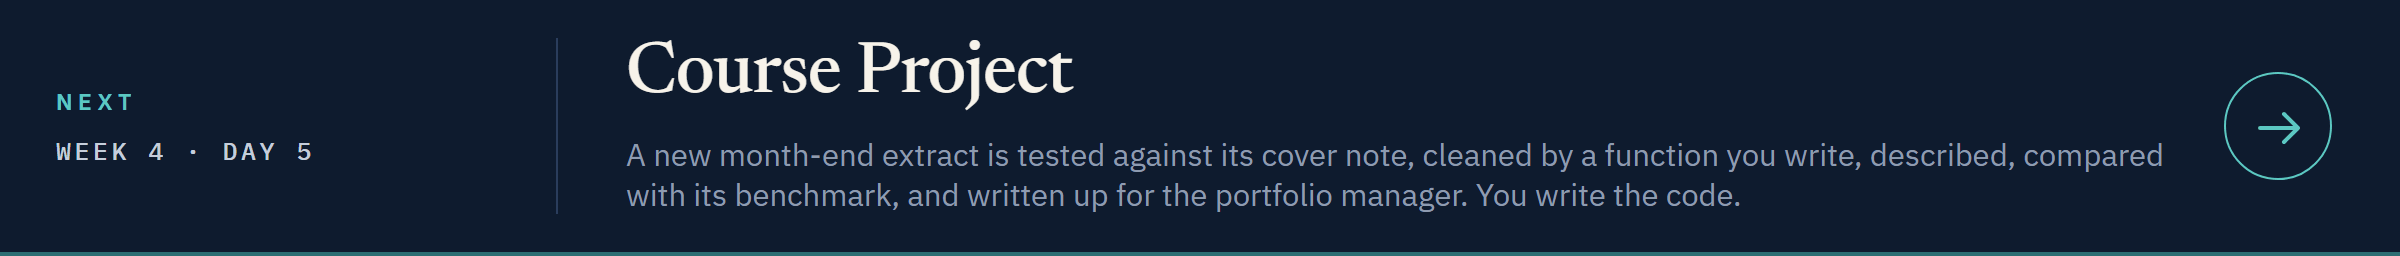](../day5/course1_project.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week4/day5/course1_project.ipynb)